In [189]:
import pandas as pd
import numpy as np

data = pd.read_csv('Data/US-pumpkins.csv')
data = data[data['Package'].str.contains('bushel')]
# data.head(40)

In [190]:
columns_selected = ['City Name', 'Variety', 'Package', 'Date', 'Origin', 'Low Price', 'High Price']
data = data.loc[:, columns_selected]
data.dropna(inplace=True)

price = (data['Low Price'] + data['High Price']) / 2
month = pd.DatetimeIndex(data['Date']).month

In [191]:
fixed_data = pd.DataFrame({
    'City': data['City Name'],
    'Variety': data['Variety'],
    'Package': data['Package'],
    'Month': month,
    'Origin': data['Origin'],
    'Price': price
})

fixed_data.loc[fixed_data['Package'].str.contains('1 1/9'), 'Price'] = price / 1.1
fixed_data.loc[fixed_data['Package'].str.contains('1/2'), 'Price'] = price * 2

fixed_data.head(50)

,City,Variety,Package,Month,Origin,Price
70,BALTIMORE,PIE TYPE,1 1/9 bushel cartons,9,DELAWARE,13.636364
71,BALTIMORE,PIE TYPE,1 1/9 bushel cartons,9,DELAWARE,16.363636
72,BALTIMORE,PIE TYPE,1 1/9 bushel cartons,10,DELAWARE,16.363636
73,BALTIMORE,PIE TYPE,1 1/9 bushel cartons,10,OHIO,15.454545
74,BALTIMORE,PIE TYPE,1 1/9 bushel cartons,10,DELAWARE,13.636364
75,BALTIMORE,PIE TYPE,1 1/9 bushel cartons,10,DELAWARE,16.363636
76,BALTIMORE,PIE TYPE,1 1/9 bushel cartons,10,OHIO,15.454545
77,BALTIMORE,PIE TYPE,1 1/9 bushel cartons,10,PENNSYLVANIA,16.136364
78,BALTIMORE,PIE TYPE,1 1/9 bushel cartons,10,DELAWARE,13.636364
79,BALTIMORE,PIE TYPE,1 1/9 bushel cartons,10,OHIO,15.454545


In [192]:
from sklearn import model_selection, linear_model
from sklearn.metrics import root_mean_squared_error as rmse
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
import matplotlib.pyplot as plt

X = (
    pd.DataFrame(fixed_data["Month"])
    .join(pd.get_dummies(fixed_data["City"], prefix="City", dtype=int))
    .join(pd.get_dummies(fixed_data["Variety"], prefix="Variety", dtype=int))
    .join(pd.get_dummies(fixed_data["Package"], prefix="Package", dtype=int))
    .join(pd.get_dummies(fixed_data["Origin"], prefix="Origin", dtype=int))
)

y = fixed_data['Price']

X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size=0.225)

In [193]:
def LinearModel1(X, y):
    model = linear_model.LinearRegression()
    model.fit(X_train, y_train)
    y_hat = model.predict(X_test)

    print(f"Linear Regression Model stats:")
    print(f"\tRMSE: {rmse(y_hat, y_test):.3f}")
    print(f"\tModel Score on Testing Dataset: {model.score(X_test, y_test):.3f}")
    print(f"\tModel Score on Training Dataset: {model.score(X_train, y_train):.3f}")
    print("\n")

    y_pred = model.predict(X)

    plt.scatter(y, y_pred, alpha=0.6)
    plt.xlabel("Giá trị thực tế")
    plt.ylabel("Giá trị dự đoán")
    plt.title("Thực tế vs. dự đoán")

    # Đường dự đoán hoàn hảo để tham khảo
    limits = [min(y.min(), y_pred.min()), max(y.max(), y_pred.max())]
    plt.plot(limits, limits, "r")
    plt.show()

def LinearModel2(X, y):
    pipeline = make_pipeline(PolynomialFeatures(2), linear_model.LinearRegression())
    pipeline.fit(X_train, y_train)
    y_hat = pipeline.predict(X_test)
    
    print(f"Polynomial Regression Model stats:")
    print(f"\tRMSE: {rmse(y_hat, y_test):.3f}")
    print(f"\tModel Score on Testing Dataset: {pipeline.score(X_test, y_test):.3f}")
    print(f"\tModel Score on Training Dataset: {pipeline.score(X_train, y_train):.3f}")
    print("\n")

    y_pred = pipeline.predict(X)

    plt.scatter(y, y_pred, alpha=0.6)
    plt.xlabel("Giá trị thực tế")
    plt.ylabel("Giá trị dự đoán")
    plt.title("Thực tế vs. dự đoán")

    # Đường dự đoán hoàn hảo để tham khảo
    limits = [min(y.min(), y_pred.min()), max(y.max(), y_pred.max())]
    plt.plot(limits, limits, "r")
    plt.show()

Linear Regression Model stats:
	RMSE: 1.905
	Model Score on Testing Dataset: 0.963
	Model Score on Training Dataset: 0.949




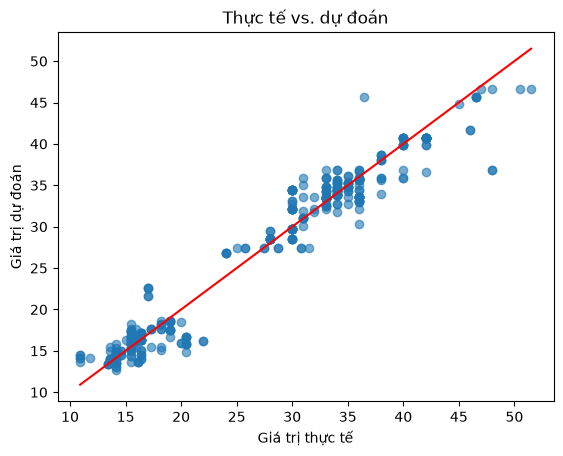

Polynomial Regression Model stats:
	RMSE: 1.904
	Model Score on Testing Dataset: 0.963
	Model Score on Training Dataset: 0.973




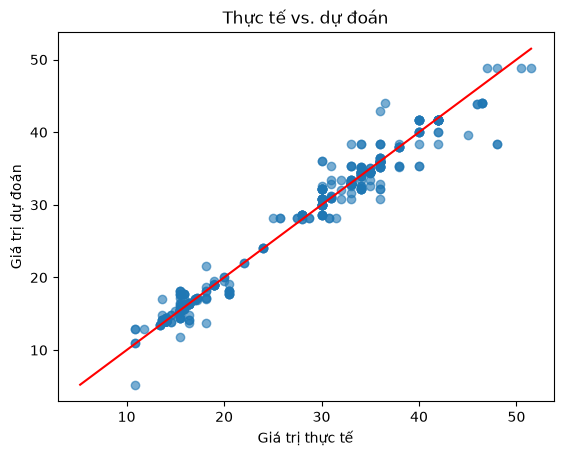

In [194]:
LinearModel1(X, y)
LinearModel2(X, y)